# Travel Insurance Dataset Project

## Introduction

Travel insurance is coverage designed to protect against risks and financial losses that could happen while traveling. The risks range from minor inconveniences such as missed airline connections and delayed luggage all the way to more serious issues including injuries or major illness (https://www.nationwide.com/lc/resources/home/articles/what-is-travel-insurance).  

Roughly 38% of travelers take travel insurances according to survey done in 2023 by businessinsider (https://www.businessinsider.com/personal-finance/travel-insurance-statistics-winter-2023-1). Main reasons for buying a travel insurance were delayed flights or moved reservations (35%). About 29% were worried about a health emergency. The majority of insured travelers (55%) purchased their policy through a travel provider.

The goal of this project is to make a model which would predict if the person is going to buy travel insurance or not, based on available data. Predictions from model can be used for targeted advertisements. Data is taken from Kaggle (https://www.kaggle.com/datasets/tejashvi14/travel-insurance-prediction-data). 

**Dataset information**

A Tour & Travels Company is offering travel insurance package to their customers. The new insurance package also includes covid cover.

The company requires to know the which customers would be interested to buy it based on its database history.
The insurance was offered to some of the customers in 2019 and the given data has been extracted from the performance/sales of the package during that period. The data is provided for almost 2000 of its previous customers and you are required to build an intelligent model that can predict if the customer will be interested to buy the travel insurance package based on certain parameters given. The solution offered by you may be used for customer specific advertising of the package.

**Project**

Travel Insurance Prediction Data is used for Supervised Machine Learning Fundamentals project of Machine Learning module sprint 1. Data analysis is done using python and pandas library. Modeling is done using scikit-learn. For visualization matplotlib and seaborn libraries were used. The project is done using Jupyter notebooks (4.1.2).

The project is done using python (version 3.11.4), numpy (1.26.1), seaborn (0.12.2), matplotlib (3.7.3), pandas (2.0.3), scikit-learn (1.3.0), statsmodels (0.14.1) and scipy (1.11.2) libraries.

**Plan**

First, I will do exploratory data analysis.

Second, I will look into three questions, regarding the features: 
* Do people who buy travel insurance have higher income?
* Is there an age difference between people who bought travel insurance and ones who did not?
* Do frequent fliers buy travel insurance more often?
And I will try to answer them using hypothesis testing and use results for modeling.

Third, I will create few models and tune their hyper-parameters:
* Logistic regression, k-nearest neighbors, support vector machine and random forest.
* After tuning the best model will be chosen, based on accuracy.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from scipy import stats
from scripts import *

In [2]:
data = pd.read_csv('data/TravelInsurancePrediction.csv')
data.head()

,Unnamed: 0,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,0,31,Government Sector,Yes,400000,6,1,No,No,0
1,1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0


In [3]:
data.shape

(1987, 10)

# Checking for nulls and duplicates

In [4]:
data.isnull().any()

Unnamed: 0             False
Age                    False
Employment Type        False
GraduateOrNot          False
AnnualIncome           False
FamilyMembers          False
ChronicDiseases        False
FrequentFlyer          False
EverTravelledAbroad    False
TravelInsurance        False
dtype: bool

In [5]:
data.duplicated().any()

False

There are no duplicates or nulls in the dataset.

In [6]:
data.set_index('Unnamed: 0', inplace=True)

In [7]:
data.index.name = None
data.head()

,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,Government Sector,Yes,400000,6,1,No,No,0
1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0


# Exploring data

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1987 entries, 0 to 1986
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Age                  1987 non-null   int64 
 1   Employment Type      1987 non-null   object
 2   GraduateOrNot        1987 non-null   object
 3   AnnualIncome         1987 non-null   int64 
 4   FamilyMembers        1987 non-null   int64 
 5   ChronicDiseases      1987 non-null   int64 
 6   FrequentFlyer        1987 non-null   object
 7   EverTravelledAbroad  1987 non-null   object
 8   TravelInsurance      1987 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 155.2+ KB


Information about features:
- Age - age of the customer
- Employment Type - the sector in which customer is employed
- GraduateOrNot - whether the customer is college graduate or not
- AnnualIncome - the yearly income of the customer in Indian rupees, rounded to nearest 50 thousand rupees.
- FamilyMembers - number of members in customer's family
- ChronicDisease - whether the customer suffers from any major disease or conditions like diabetes/high BP or asthma, etc.
- FrequentFlyer - derived data based on customer's history of booking air tickets on at least 4 different instances in the last 2 years (2017 – 2019).
- EverTravelledAbroad - has the customer ever traveled to a foreign country, not necessarily using the company's services.
- TravelInsurance - did the customer buy travel insurance package during introductory offering held in the year 2019.

In [9]:
for i in data.columns:
    print(i, "column's total unique values are:", data[i].nunique())

Age column's total unique values are: 11
Employment Type column's total unique values are: 2
GraduateOrNot column's total unique values are: 2
AnnualIncome column's total unique values are: 30
FamilyMembers column's total unique values are: 8
ChronicDiseases column's total unique values are: 2
FrequentFlyer column's total unique values are: 2
EverTravelledAbroad column's total unique values are: 2
TravelInsurance column's total unique values are: 2


In [10]:
for i in data.columns:
    print(i, "column's unique values are:", data[i].unique())

Age column's unique values are: [31 34 28 25 33 26 32 29 35 30 27]
Employment Type column's unique values are: ['Government Sector' 'Private Sector/Self Employed']
GraduateOrNot column's unique values are: ['Yes' 'No']
AnnualIncome column's unique values are: [ 400000 1250000  500000  700000 1150000 1300000 1350000 1450000  800000
 1400000  850000 1500000 1050000  350000 1100000  600000  900000  550000
  300000  750000 1200000 1000000  950000 1700000 1750000  650000  450000
 1650000 1800000 1550000]
FamilyMembers column's unique values are: [6 7 4 3 8 9 5 2]
ChronicDiseases column's unique values are: [1 0]
FrequentFlyer column's unique values are: ['No' 'Yes']
EverTravelledAbroad column's unique values are: ['No' 'Yes']
TravelInsurance column's unique values are: [0 1]


In [11]:
empl_type_counts = data['Employment Type'].value_counts()
graduate_counts = data['GraduateOrNot'].value_counts()
chronic_counts = data['ChronicDiseases'].value_counts()
flyer_counts = data['FrequentFlyer'].value_counts()
travel_abroad_counts = data['EverTravelledAbroad'].value_counts()
travel_insurance_counts = data['TravelInsurance'].value_counts()

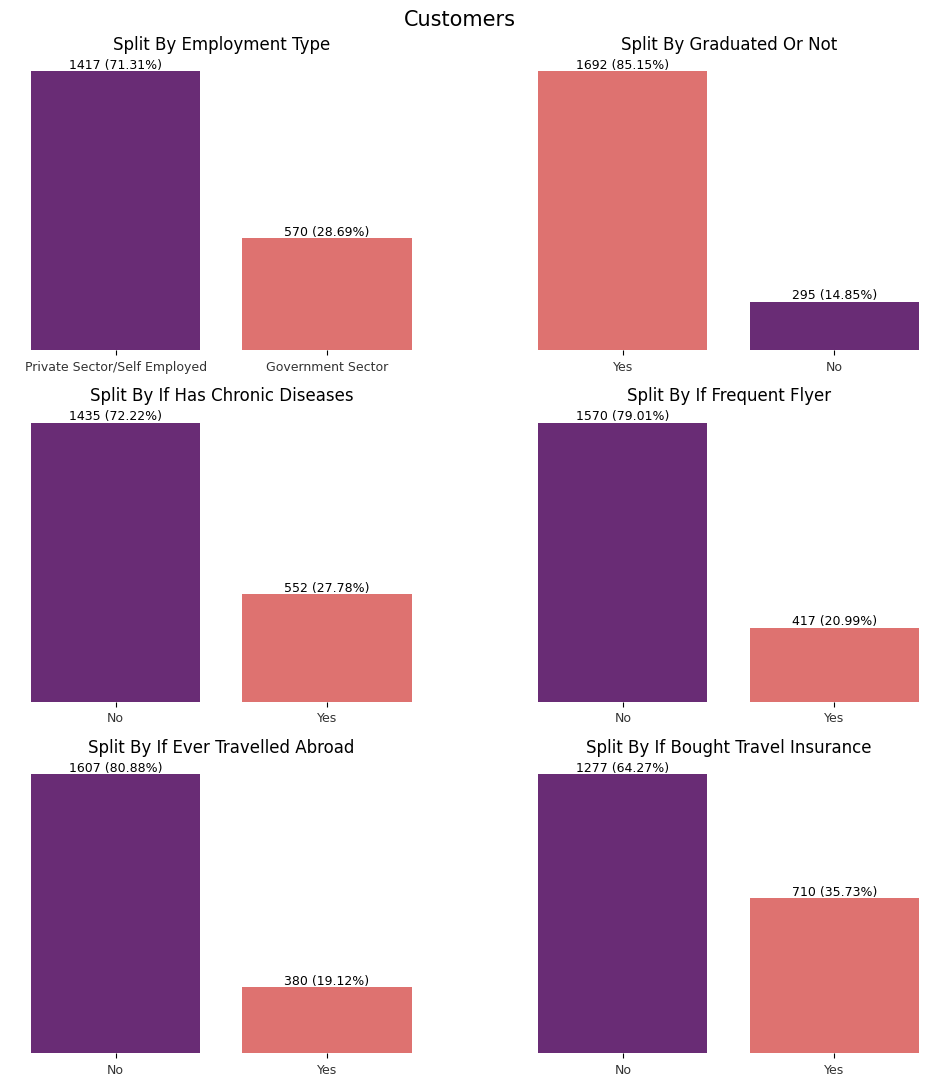

In [12]:
fig, axs = plt.pyplot.subplots(3, 2, figsize=(12, 12))

fig.suptitle('Customers', fontsize=15)
fig.subplots_adjust(top=0.94)

ax1 = bar_plot_f_perc(empl_type_counts, 'magma', 'Split By Employment Type', ax=axs[0, 0])
ax2 = bar_plot_f_perc(graduate_counts, 'magma_r', 'Split By Graduated Or Not', ax=axs[0, 1])
ax3 = bar_plot_f_perc(chronic_counts, 'magma', 'Split By If Has Chronic Diseases', ax=axs[1, 0])
ax4 = bar_plot_f_perc(flyer_counts, 'magma', 'Split By If Frequent Flyer', ax=axs[1, 1])
ax5 = bar_plot_f_perc(travel_abroad_counts, 'magma', 'Split By If Ever Travelled Abroad', ax=axs[2, 0])
ax6 = bar_plot_f_perc(travel_insurance_counts, 'magma', 'Split By If Bought Travel Insurance', ax=axs[2, 1])

ax3.set_xticklabels(['No', 'Yes'])
ax6.set_xticklabels(['No', 'Yes'])

sns.despine(left=True, bottom=True)

The dataset is unbalanced, since some classes more frequent than others.

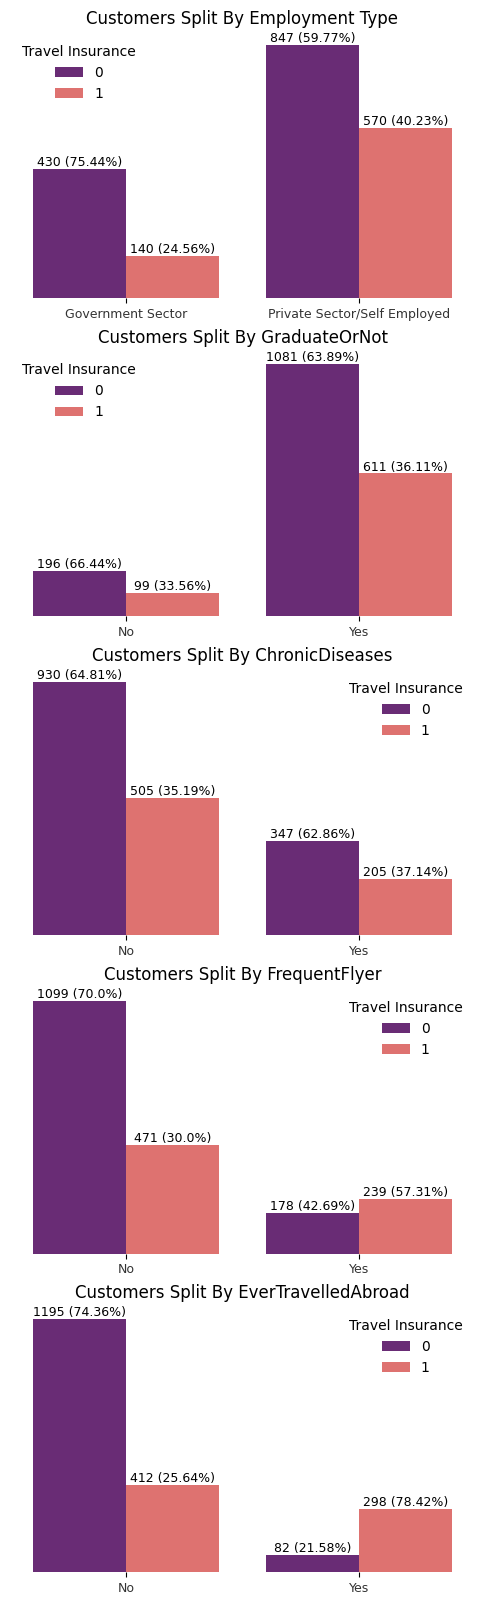

In [13]:
fig, axs = plt.pyplot.subplots(5, 1, figsize=(6, 20))

features = ['Employment Type', 'GraduateOrNot', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad']
i = 0
for item in features:
    temp = data.groupby(item)['TravelInsurance'].value_counts()
    ax = bar_plot_multi_index_f(temp, item, 'TravelInsurance', f'Customers Split By {item}', 'magma', ax=axs[i])
    ax.legend(edgecolor='none', title='Travel Insurance')
    if item == 'ChronicDiseases':
        ax.set_xticklabels(['No', 'Yes'])
    i += 1

sns.despine(left=True, bottom=True)

It looks like, ever traveling abroad is the most important factor in buying the travel insurance, as about 78% bought it and only 22% didn't. There were also more frequent fliers who bought the insurance compared to ones who didn't. In rest of the groups there are always more customers who didn't buy the insurance.

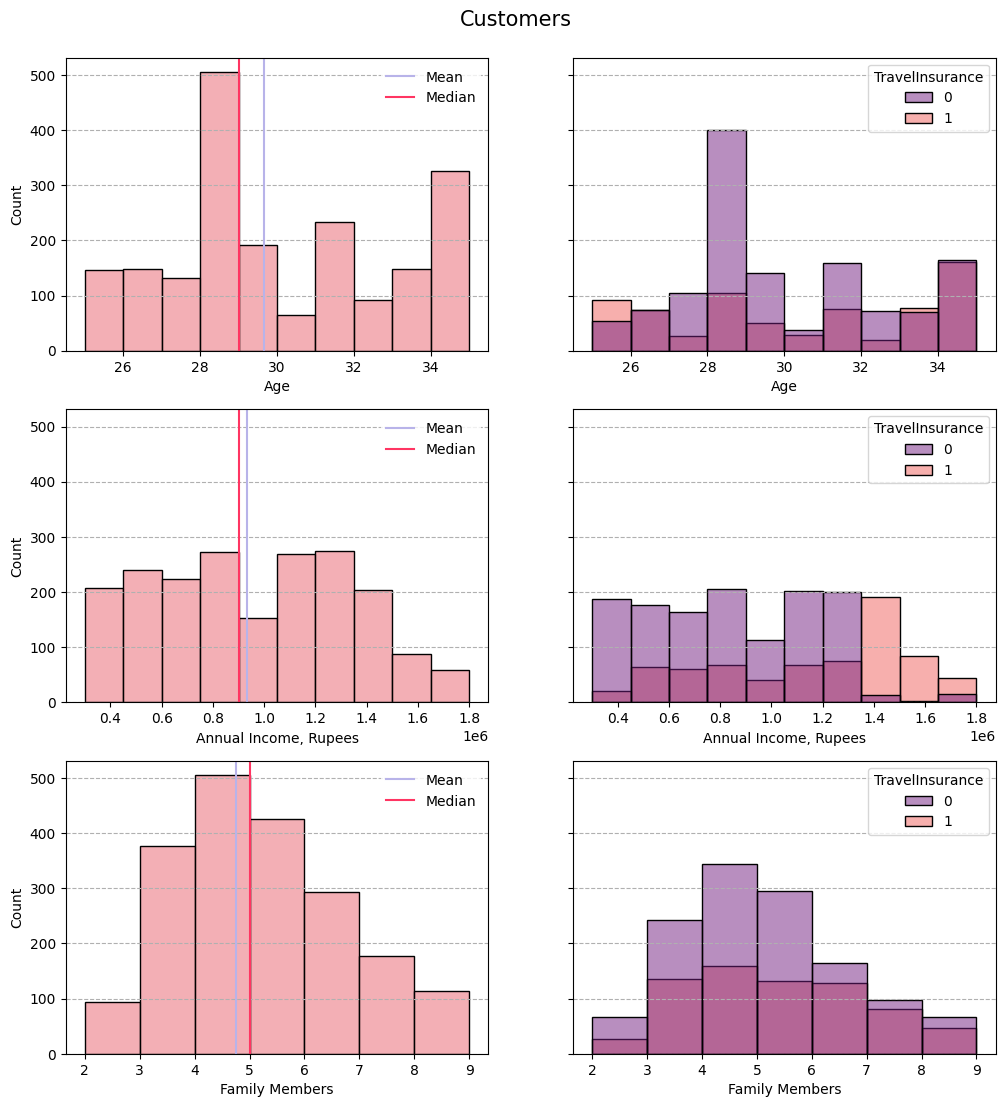

In [14]:
fig, axs = plt.pyplot.subplots(3, 2, figsize=(12, 12), sharey=True)

fig.suptitle('Customers', fontsize=15)
fig.subplots_adjust(top=0.94)

ax00 = histplot_f(data.Age, color='#EF959D', color_median='#FF3562', binwidth=1, ax=axs[0, 0])
ax01 = sns.histplot(data=data, x='Age', hue='TravelInsurance', palette='magma', binwidth=1, ax=axs[0, 1])
ax01.grid(axis='y', linestyle='--')

ax10 = histplot_f(data.AnnualIncome, color='#EF959D', color_median='#FF3562', binwidth=150000, ax=axs[1, 0])
ax10.set(xlabel='Annual Income, Rupees')
ax11 = sns.histplot(data=data, x='AnnualIncome', hue='TravelInsurance', palette='magma', binwidth=150000, ax=axs[1, 1])
ax11.set(xlabel='Annual Income, Rupees')
ax11.grid(axis='y', linestyle='--')

ax20 = histplot_f(data.FamilyMembers, color='#EF959D', color_median='#FF3562', binwidth=1, ax=axs[2, 0])
ax20.set(xlabel='Family Members')
ax21 = sns.histplot(data=data, x='FamilyMembers', hue='TravelInsurance', palette='magma', binwidth=1, ax=axs[2, 1])
ax21.set(xlabel='Family Members')
ax21.grid(axis='y', linestyle='--');

Distribution for family member number is approximately normal, with peak at 4 family members, and skewed to the right a little bit. Annual income and age of customers seems do not look like they are distributed normally. There is a peak of customers of around age 28 and rest is distributed approximately uniformly. Annual income is also distributed approximately uniformly, with a lowering in the amount of customers having a higher income.

On the left we can see differences between people who bought the travel insurance (marked as 1 in the legend) and who didn't (marked as 0 in the legend). We can see that there isn't a peak of customers around age 28 for customers who bought the insurance. The distribution for income for people who bought the insurance, has a peak at 1.4 million rupees and is skewed to the left. From 1.4 million rupees there aren't many customers who didn't buy the insurance. Family member number is distributed more uniformly for ones who bought the insurance and doesn't have as big of a peak at 4 compared to ones who did not buy the insurance.

In [15]:
# Coverting categorical to numerics
data['Employment Type'] = data['Employment Type'].map({'Private Sector/Self Employed': 1, 'Government Sector': 0})
data['GraduateOrNot'] = data['GraduateOrNot'].map({'Yes': 1, 'No': 0})
data['FrequentFlyer'] = data['FrequentFlyer'].map({'Yes': 1, 'No': 0})
data['EverTravelledAbroad'] = data['EverTravelledAbroad'].map({'Yes': 1, 'No': 0})
data.head()

,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,0,1,400000,6,1,0,0,0
1,31,1,1,1250000,7,0,0,0,0
2,34,1,1,500000,4,1,0,0,1
3,28,1,1,700000,3,1,0,0,0
4,28,1,1,700000,8,1,1,0,0


In [16]:
data.describe()

,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
count,1987.000000,1987.000000,1987.000000,1.987000e+03,1987.000000,1987.000000,1987.000000,1987.000000,1987.000000
mean,29.650226,0.713135,0.851535,9.327630e+05,4.752894,0.277806,0.209864,0.191243,0.357323
std,2.913308,0.452412,0.355650,3.768557e+05,1.609650,0.448030,0.407314,0.393379,0.479332
min,25.000000,0.000000,0.000000,3.000000e+05,2.000000,0.000000,0.000000,0.000000,0.000000
25%,28.000000,0.000000,1.000000,6.000000e+05,4.000000,0.000000,0.000000,0.000000,0.000000
50%,29.000000,1.000000,1.000000,9.000000e+05,5.000000,0.000000,0.000000,0.000000,0.000000
75%,32.000000,1.000000,1.000000,1.250000e+06,6.000000,1.000000,0.000000,0.000000,1.000000
max,35.000000,1.000000,1.000000,1.800000e+06,9.000000,1.000000,1.000000,1.000000,1.000000


In [17]:
outliers = outlier_f(data)
outliers.sum()

Age                      0.0
Employment Type          0.0
GraduateOrNot            0.0
AnnualIncome             0.0
FamilyMembers            0.0
ChronicDiseases          0.0
FrequentFlyer          417.0
EverTravelledAbroad    380.0
TravelInsurance          0.0
dtype: float64

All of the outliers found by the function are just rarer values converted from categorical values - there are much less frequent fliers and people ever traveled abroad compared to the rest of the customers. There are no actual outliers in the dataset.

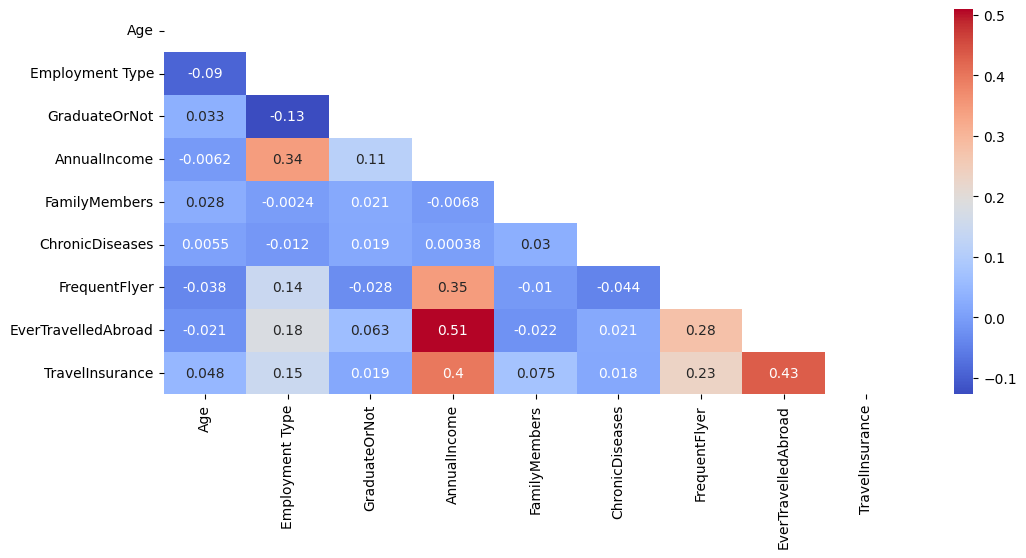

In [18]:
# Spearman correlation assumes monotonic relationships
corr = data.corr(method='spearman')

fig = plt.pyplot.figure(figsize=(12, 5))

# To make a triangle mask
mask = np.triu(np.ones_like(corr))

corr_plot = sns.heatmap(corr, cmap=sns.color_palette("coolwarm", as_cmap=True), annot=True, mask=mask)

We can see that having higher annual income correlates with buying travel insurance, traveling abroad and being a frequent flier. It makes sense as people with higher income have more money available for more expensive leisure activities. Being a frequent flier and ever traveling abroad also correlates with buying the insurance. 

There are no strong correlations (0.75 or more), therefore all of the features will be kept.

# Perform statistical inference

After exploring the data, we are going to compare people who did buy the insurance and ones who didn't, using hypothesis testing. Here are 3 questions I will try to answer:

- Do people who buy insurance have higher income?
- Is there a difference in age between ones who bought the insurance and ones who didn't?
- Are frequent buyers more likely to buy the insurance?

We can try to answer these questions using the data. Hypothesis testing will be applied to check if there is any statistical significance. $ H_0 $ will always be that there is no difference, and $ H_1 $ accordingly will be that there is a difference. Chosen significance level – $ α $ will be 5% (or 0.05). Since there are few hypotheses Bonferroni Correction will be used: $ α $ is going to be divided by the number of hypotheses made – 3 (which results to roughly 0.0167).

The results will determine whether or not the feature is going to be taken for modeling.

In [19]:
mask = data['TravelInsurance'] == 1

bought_insurance = data[mask]
didnt_buy_insurance = data[~mask]

assert len(didnt_buy_insurance) + len(bought_insurance) == len(data)

## Hypothesis 1

Do people who buy insurance have higher income?

$ H_0 $ will be that there is no difference between income amounts. $ H_1 $ will be that there is a difference.

T test is going to be used to check if there is a statistical difference.

In [20]:
bought_ins_income = bought_insurance.AnnualIncome
bought_ins_income.describe()

count    7.100000e+02
mean     1.133239e+06
std      3.748447e+05
min      3.000000e+05
25%      8.000000e+05
50%      1.250000e+06
75%      1.400000e+06
max      1.800000e+06
Name: AnnualIncome, dtype: float64

In [21]:
didnt_buy_ins_income = didnt_buy_insurance.AnnualIncome
didnt_buy_ins_income.describe()

count    1.277000e+03
mean     8.212999e+05
std      3.288989e+05
min      3.000000e+05
25%      5.500000e+05
50%      8.000000e+05
75%      1.100000e+06
max      1.750000e+06
Name: AnnualIncome, dtype: float64

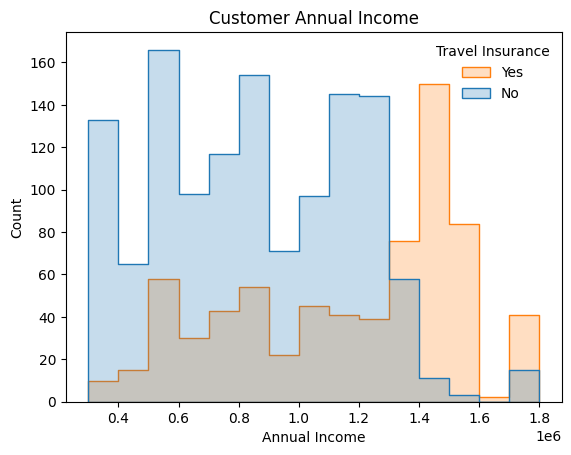

In [22]:
ax1 = sns.histplot(data=data, x="AnnualIncome", hue="TravelInsurance", element="step")
ax1.set(title="Customer Annual Income", xlabel='Annual Income')
ax1.legend(title='Travel Insurance', labels=['Yes', 'No'], frameon=False);

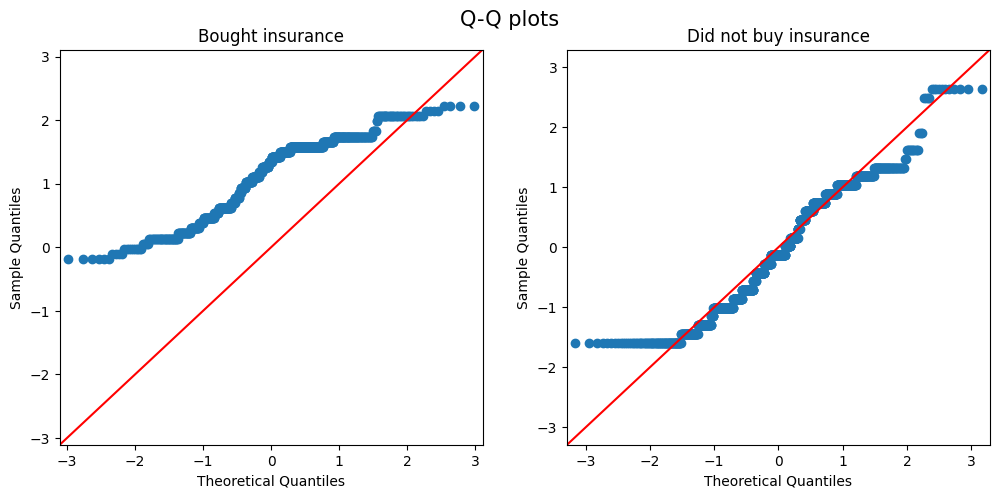

In [23]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(12, 5))

fig.suptitle('Q-Q plots', fontsize=15)
fig.subplots_adjust(top=0.90)

ax1 = sm.qqplot(bought_ins_income, stats.t, fit=True, line="45", ax=axs[0])
ax2 = sm.qqplot(didnt_buy_ins_income, stats.t, fit=True, line="45", ax=axs[1])

axs[0].set_title('Bought insurance')
axs[1].set_title('Did not buy insurance');

We can see deviations from theoretical quantiles, which indicates that the distributions are not normal as they are rather over-dispersed. Distribution for customers who didn't buy the insurance follows the middle line more closely. 

However, since we have a lot of observations we can also apply central limit theorem and test hypothesis.

In [24]:
stats.ttest_ind(bought_ins_income, didnt_buy_ins_income)

TtestResult(statistic=19.257785253687544, pvalue=6.63501776035329e-76, df=1985.0)

In [25]:
conf_int_bought_ins_inc = stats.t.interval(
    0.95, df=len(bought_ins_income) - 1, loc=bought_ins_income.mean(), scale=bought_ins_income.sem()
)
conf_int_bought_ins_inc

(1105620.1612810094, 1160858.7119584272)

In [26]:
conf_int_didnt_buy_ins_inc = stats.t.interval(
    0.95, df=len(didnt_buy_ins_income) - 1, loc=didnt_buy_ins_income.mean(), scale=didnt_buy_ins_income.sem()
)
conf_int_didnt_buy_ins_inc

(803243.6864898786, 839356.1568930502)

In addition we can check Mood’s median test and Mann-Whitney U test to check if this result holds up.

In [27]:
stats.mannwhitneyu(bought_ins_income, didnt_buy_ins_income)

MannwhitneyuResult(statistic=670230.5, pvalue=3.0201010454885667e-70)

In [28]:
stats.median_test(bought_ins_income, didnt_buy_ins_income)

MedianTestResult(statistic=162.6500660759668, pvalue=2.9831121619018706e-37, median=900000.0, table=array([[484, 488],
       [226, 789]], dtype=int64))

According to the results of hypothesis testing, there is a statistical difference in income between ones who bought the insurance and ones who didn't. People who tend to buy travel insurance tend to have higher income.

## Hypothesis 2

Is there a difference in age between ones who bought the insurance and ones who didn't?

$ H_0 $ will be that there is no difference. $ H_1 $ will be that there is a difference.

T test is going to be used to check if there is a statistical difference.

In [29]:
bought_ins_age = bought_insurance.Age
bought_ins_age.describe()

count    710.000000
mean      29.888732
std        3.331732
min       25.000000
25%       27.000000
50%       30.000000
75%       33.000000
max       35.000000
Name: Age, dtype: float64

In [30]:
didnt_buy_ins_age = didnt_buy_insurance.Age
didnt_buy_ins_age.describe()

count    1277.000000
mean       29.517619
std         2.644396
min        25.000000
25%        28.000000
50%        29.000000
75%        31.000000
max        35.000000
Name: Age, dtype: float64

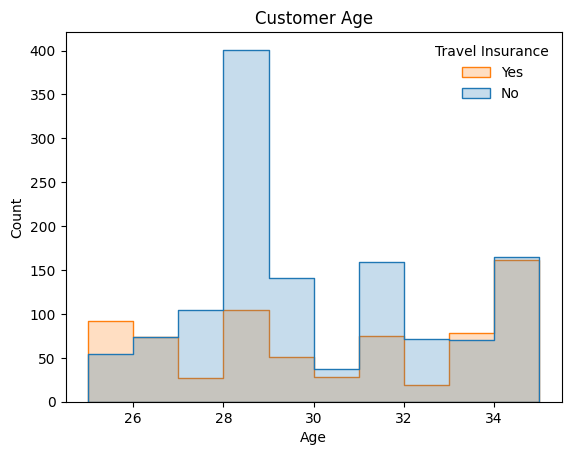

In [31]:
ax1 = sns.histplot(data=data, x="Age", hue="TravelInsurance", element="step", binwidth=1)
ax1.set(title="Customer Age")
ax1.legend(title='Travel Insurance', labels=['Yes', 'No'], frameon=False);

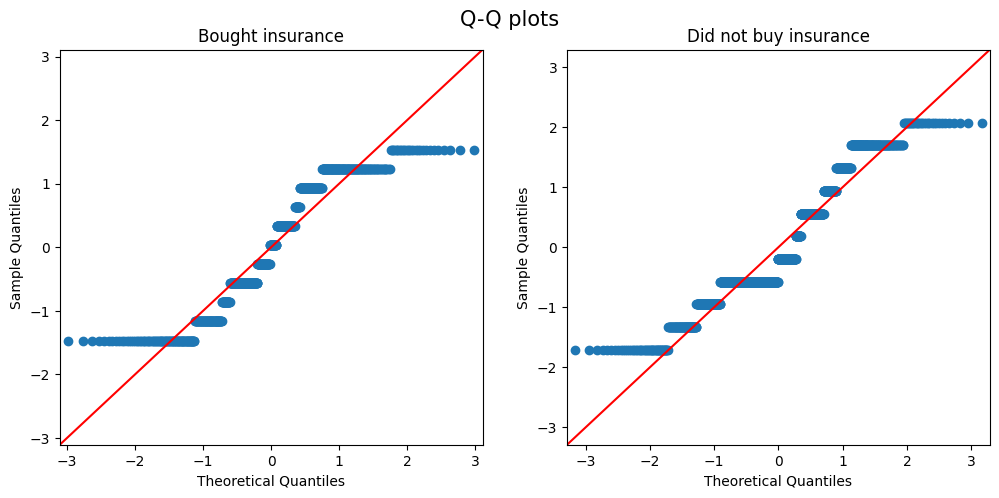

In [32]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(12, 5))

fig.suptitle('Q-Q plots', fontsize=15)
fig.subplots_adjust(top=0.90)

ax1 = sm.qqplot(bought_ins_age, stats.t, fit=True, line="45", ax=axs[0])
ax2 = sm.qqplot(didnt_buy_ins_age, stats.t, fit=True, line="45", ax=axs[1])

axs[0].set_title('Bought insurance')
axs[1].set_title('Did not buy insurance');

We can see deviations from theoretical quantiles, which indicates that the distributions are not normal as they are rather over-dispersed. Distribution for customers who didn't buy the insurance follows the middle line more closely. 

However, since we have a lot of observations we can also apply central limit theorem and test hypothesis.

In [33]:
stats.ttest_ind(bought_ins_age, didnt_buy_ins_age)

TtestResult(statistic=2.7255058475523968, pvalue=0.006476683978749601, df=1985.0)

In [34]:
stats.mannwhitneyu(bought_ins_age, didnt_buy_ins_age)

MannwhitneyuResult(statistic=479515.0, pvalue=0.030678780881604334)

In [35]:
stats.median_test(bought_ins_age, didnt_buy_ins_age)

MedianTestResult(statistic=23.903536222276614, pvalue=1.012855391615658e-06, median=29.0, table=array([[361, 503],
       [349, 774]], dtype=int64))

We cannot say with confidence that there is a statistical difference between ages in both groups, as it did fail the Mann-Whitney U test and p value is higher than our set limit (0.0167). Also practically the average age difference looks insignificant (29.89 for ones who bought the insurance vs 29.52 ones who didn't). However, the age feature is going to be kept for modeling, because it did pass t test and median test (as they show statistical significance), and it might be somewhat significant in determining if the customer is going to buy the insurance or not.

## Hypothesis 3

Are frequent buyers more likely to buy the insurance?

$ H_0 $ will be that there is no difference and people who fly frequent are not likely to buy the insurance more often than ones who don't. $ H_1 $ will be that there is a difference.

Chi-square test is going to be used to check if there is a statistical difference.

In [36]:
bought_ins_flyer = bought_insurance.FrequentFlyer
bought_ins_flyer.describe()

count    710.000000
mean       0.336620
std        0.472887
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: FrequentFlyer, dtype: float64

In [37]:
didnt_buy_ins_flyer = didnt_buy_insurance.FrequentFlyer
didnt_buy_ins_flyer.describe()

count    1277.000000
mean        0.139389
std         0.346488
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: FrequentFlyer, dtype: float64

In [38]:
flyers = data.groupby('TravelInsurance').FrequentFlyer.value_counts()
flyers = flyers.unstack().rename(columns={0: 'No', 1: 'Yes'}, index={0: 'No', 1: 'Yes'})
flyers

FrequentFlyer,No,Yes
TravelInsurance,,
No,1099,178
Yes,471,239


In [39]:
stats.chi2_contingency(flyers)

Chi2ContingencyResult(statistic=105.85723074203977, pvalue=7.92436041506454e-25, dof=1, expected_freq=array([[1009.0035229,  267.9964771],
       [ 560.9964771,  149.0035229]]))

We can say that there is a statistical difference between two groups and reject the null hypothesis. Frequent fliers do tend to buy travel insurance more often than ones who do not.

# Modeling

Majority of customers do not buy travel insurance. Goal is to have accuracy higher than 64.27%, which is the percentage of people who do not buy the travel insurance.

## Dividing into train, test and validation sets

In [40]:
x = data.iloc[:, :-1]
y = data["TravelInsurance"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=0, stratify=data["TravelInsurance"]
)

In [41]:
# Somme models require features to be scaled, for example
# saga solver in logistic regresion.
scaler = MinMaxScaler()
X = scaler.fit_transform(x_train)
x_test_scaled = scaler.fit_transform(x_test)

## Logistic regresion

In [42]:
# define models and parameters
model = LogisticRegression(random_state=0)

# Some combinations were omitted to cut back on the warnings/errors
solvers = ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']
penalty = [
    'l2',
]
c_values = [100, 10, 1.0, 0.1, 0.01]

# define grid search
grid = dict(solver=solvers, penalty=penalty, C=c_values)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='accuracy', error_score=0)
grid_result = grid_search.fit(X, y_train)

# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.765258 using {'C': 100, 'penalty': 'l2', 'solver': 'newton-cg'}
0.765258 (0.008428) with: {'C': 100, 'penalty': 'l2', 'solver': 'newton-cg'}
0.765258 (0.008428) with: {'C': 100, 'penalty': 'l2', 'solver': 'lbfgs'}
0.765258 (0.008428) with: {'C': 100, 'penalty': 'l2', 'solver': 'liblinear'}
0.765258 (0.008428) with: {'C': 100, 'penalty': 'l2', 'solver': 'sag'}
0.765258 (0.008428) with: {'C': 100, 'penalty': 'l2', 'solver': 'saga'}
0.765256 (0.008007) with: {'C': 10, 'penalty': 'l2', 'solver': 'newton-cg'}
0.765256 (0.008007) with: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
0.764625 (0.008717) with: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
0.765256 (0.008007) with: {'C': 10, 'penalty': 'l2', 'solver': 'sag'}
0.765256 (0.008007) with: {'C': 10, 'penalty': 'l2', 'solver': 'saga'}
0.762730 (0.012787) with: {'C': 1.0, 'penalty': 'l2', 'solver': 'newton-cg'}
0.762730 (0.012787) with: {'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs'}
0.759586 (0.011438) with: {'C': 1.0, 'penal

Note: best one here is the default: lbfgs since the results are same as newton-cg. Default (lbfgs) relatively performs well compared to other methods and it saves a lot of memory, however, sometimes it may have issues with convergence.  

## K-Nearest Neighbors (KNN)

In [43]:
model = KNeighborsClassifier()

# From 1 to 10 neighbors
n_neighbors = range(1, 11, 1)
weights = ['uniform', 'distance']
metric = ['euclidean', 'manhattan', 'minkowski']

# define grid search
grid = dict(n_neighbors=n_neighbors, weights=weights, metric=metric)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='accuracy', error_score=0)
grid_result = grid_search.fit(x_train, y_train)

# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.813094 using {'metric': 'euclidean', 'n_neighbors': 8, 'weights': 'uniform'}
0.756445 (0.013383) with: {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'}
0.756445 (0.013383) with: {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'distance'}
0.789177 (0.006229) with: {'metric': 'euclidean', 'n_neighbors': 2, 'weights': 'uniform'}
0.782888 (0.007001) with: {'metric': 'euclidean', 'n_neighbors': 2, 'weights': 'distance'}
0.791070 (0.007687) with: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'uniform'}
0.789812 (0.012525) with: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'}
0.813089 (0.011025) with: {'metric': 'euclidean', 'n_neighbors': 4, 'weights': 'uniform'}
0.795469 (0.018553) with: {'metric': 'euclidean', 'n_neighbors': 4, 'weights': 'distance'}
0.806801 (0.011625) with: {'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'uniform'}
0.793582 (0.020524) with: {'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}
0.811210 (

In [44]:
model = KNeighborsClassifier()

# From 1 to 10 neighbors
n_neighbors = range(1, 11, 1)
weights = ['uniform', 'distance']
metric = ['euclidean', 'manhattan', 'minkowski']

# define grid search
grid = dict(n_neighbors=n_neighbors, weights=weights, metric=metric)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='accuracy', error_score=0)

# using scaled features
grid_result = grid_search.fit(X, y_train)

# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.797357 using {'metric': 'euclidean', 'n_neighbors': 4, 'weights': 'uniform'}
0.726863 (0.023248) with: {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'}
0.726863 (0.023248) with: {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'distance'}
0.769665 (0.016110) with: {'metric': 'euclidean', 'n_neighbors': 2, 'weights': 'uniform'}
0.752045 (0.013114) with: {'metric': 'euclidean', 'n_neighbors': 2, 'weights': 'distance'}
0.769684 (0.018180) with: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'uniform'}
0.759610 (0.011461) with: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'}
0.797357 (0.020910) with: {'metric': 'euclidean', 'n_neighbors': 4, 'weights': 'uniform'}
0.763377 (0.013910) with: {'metric': 'euclidean', 'n_neighbors': 4, 'weights': 'distance'}
0.794836 (0.014314) with: {'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'uniform'}
0.775323 (0.016337) with: {'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}
0.794851 (

## Support Vector Machine (SVM)

In [45]:
# define model and parameters
model = SVC(random_state=0)
kernel = ['poly', 'rbf', 'sigmoid']
C = [50, 10, 1.0, 0.1, 0.01]
gamma = ['scale']

# define grid search
grid = dict(kernel=kernel, C=C, gamma=gamma)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='accuracy', error_score=0)
grid_result = grid_search.fit(x_train, y_train)

# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.775962 using {'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}
0.747632 (0.008768) with: {'C': 50, 'gamma': 'scale', 'kernel': 'poly'}
0.773446 (0.005101) with: {'C': 50, 'gamma': 'scale', 'kernel': 'rbf'}
0.489632 (0.024155) with: {'C': 50, 'gamma': 'scale', 'kernel': 'sigmoid'}
0.747632 (0.008768) with: {'C': 10, 'gamma': 'scale', 'kernel': 'poly'}
0.773446 (0.005101) with: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
0.489632 (0.024155) with: {'C': 10, 'gamma': 'scale', 'kernel': 'sigmoid'}
0.747632 (0.008768) with: {'C': 1.0, 'gamma': 'scale', 'kernel': 'poly'}
0.775962 (0.007213) with: {'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}
0.500952 (0.010977) with: {'C': 1.0, 'gamma': 'scale', 'kernel': 'sigmoid'}
0.747632 (0.008768) with: {'C': 0.1, 'gamma': 'scale', 'kernel': 'poly'}
0.769044 (0.013616) with: {'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}
0.535559 (0.010514) with: {'C': 0.1, 'gamma': 'scale', 'kernel': 'sigmoid'}
0.747632 (0.008768) with: {'C': 0.01, 'gamma': 'scale',

In [46]:
# define model and parameters
model = SVC(random_state=0)
kernel = ['linear', 'poly', 'rbf', 'sigmoid']
C = [50, 10, 1.0, 0.1, 0.01]

# define grid search
grid = dict(kernel=kernel, C=C)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='accuracy', error_score=0)

# using scaled features
grid_result = grid_search.fit(X, y_train)

# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.812468 using {'C': 50, 'kernel': 'poly'}
0.750146 (0.011619) with: {'C': 50, 'kernel': 'linear'}
0.812468 (0.007435) with: {'C': 50, 'kernel': 'poly'}
0.806172 (0.010167) with: {'C': 50, 'kernel': 'rbf'}
0.497163 (0.017636) with: {'C': 50, 'kernel': 'sigmoid'}
0.750146 (0.011619) with: {'C': 10, 'kernel': 'linear'}
0.811825 (0.007455) with: {'C': 10, 'kernel': 'poly'}
0.804906 (0.009583) with: {'C': 10, 'kernel': 'rbf'}
0.497163 (0.017636) with: {'C': 10, 'kernel': 'sigmoid'}
0.750146 (0.011619) with: {'C': 1.0, 'kernel': 'linear'}
0.794836 (0.007388) with: {'C': 1.0, 'kernel': 'poly'}
0.780350 (0.012448) with: {'C': 1.0, 'kernel': 'rbf'}
0.507234 (0.016568) with: {'C': 1.0, 'kernel': 'sigmoid'}
0.750146 (0.011619) with: {'C': 0.1, 'kernel': 'linear'}
0.780975 (0.015529) with: {'C': 0.1, 'kernel': 'poly'}
0.752037 (0.010623) with: {'C': 0.1, 'kernel': 'rbf'}
0.602905 (0.011846) with: {'C': 0.1, 'kernel': 'sigmoid'}
0.750146 (0.011619) with: {'C': 0.01, 'kernel': 'linear'}
0.755

In [47]:
# define model and parameters
model = SVC(random_state=0)
kernel = ['poly', 'rbf']
C = [50, 49, 51]
degree = [1, 2, 3, 4]

# define grid search
grid = dict(kernel=kernel, C=C, degree=degree)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='accuracy', error_score=0)

# using scaled features
grid_result = grid_search.fit(X, y_train)

# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.812468 using {'C': 50, 'degree': 3, 'kernel': 'poly'}
0.750146 (0.011619) with: {'C': 50, 'degree': 1, 'kernel': 'poly'}
0.806172 (0.010167) with: {'C': 50, 'degree': 1, 'kernel': 'rbf'}
0.780350 (0.014503) with: {'C': 50, 'degree': 2, 'kernel': 'poly'}
0.806172 (0.010167) with: {'C': 50, 'degree': 2, 'kernel': 'rbf'}
0.812468 (0.007435) with: {'C': 50, 'degree': 3, 'kernel': 'poly'}
0.806172 (0.010167) with: {'C': 50, 'degree': 3, 'kernel': 'rbf'}
0.808061 (0.010423) with: {'C': 50, 'degree': 4, 'kernel': 'poly'}
0.806172 (0.010167) with: {'C': 50, 'degree': 4, 'kernel': 'rbf'}
0.750146 (0.011619) with: {'C': 49, 'degree': 1, 'kernel': 'poly'}
0.806801 (0.010174) with: {'C': 49, 'degree': 1, 'kernel': 'rbf'}
0.780350 (0.014503) with: {'C': 49, 'degree': 2, 'kernel': 'poly'}
0.806801 (0.010174) with: {'C': 49, 'degree': 2, 'kernel': 'rbf'}
0.812468 (0.007435) with: {'C': 49, 'degree': 3, 'kernel': 'poly'}
0.806801 (0.010174) with: {'C': 49, 'degree': 3, 'kernel': 'rbf'}
0.80806

## Random Forest

In [48]:
# define models and parameters
model = RandomForestClassifier(random_state=0)
n_estimators = [10, 100, 500, 600, 700, 1000]
max_features = ['sqrt', 'log2']

# define grid search
grid = dict(n_estimators=n_estimators, max_features=max_features)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='accuracy', error_score=0)
grid_result = grid_search.fit(x_train, y_train)

# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.791060 using {'max_features': 'log2', 'n_estimators': 600}
0.777222 (0.005272) with: {'max_features': 'sqrt', 'n_estimators': 10}
0.789810 (0.016503) with: {'max_features': 'sqrt', 'n_estimators': 100}
0.789808 (0.022854) with: {'max_features': 'sqrt', 'n_estimators': 500}
0.789808 (0.022151) with: {'max_features': 'sqrt', 'n_estimators': 600}
0.789808 (0.022854) with: {'max_features': 'sqrt', 'n_estimators': 700}
0.789179 (0.022729) with: {'max_features': 'sqrt', 'n_estimators': 1000}
0.780362 (0.010465) with: {'max_features': 'log2', 'n_estimators': 10}
0.790427 (0.016684) with: {'max_features': 'log2', 'n_estimators': 100}
0.790431 (0.021134) with: {'max_features': 'log2', 'n_estimators': 500}
0.791060 (0.021417) with: {'max_features': 'log2', 'n_estimators': 600}
0.790431 (0.021134) with: {'max_features': 'log2', 'n_estimators': 700}
0.789173 (0.022434) with: {'max_features': 'log2', 'n_estimators': 1000}


In [49]:
# define models and parameters
model = RandomForestClassifier(random_state=0)
n_estimators = [10, 100, 400, 494, 495, 496, 500, 600]
max_features = ['sqrt', 'log2']

# define grid search
grid = dict(n_estimators=n_estimators, max_features=max_features)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='accuracy', error_score=0)
grid_result = grid_search.fit(X, y_train)

# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.791697 using {'max_features': 'sqrt', 'n_estimators': 495}
0.778479 (0.004585) with: {'max_features': 'sqrt', 'n_estimators': 10}
0.791068 (0.016174) with: {'max_features': 'sqrt', 'n_estimators': 100}
0.791064 (0.021653) with: {'max_features': 'sqrt', 'n_estimators': 400}
0.791068 (0.021617) with: {'max_features': 'sqrt', 'n_estimators': 494}
0.791697 (0.020857) with: {'max_features': 'sqrt', 'n_estimators': 495}
0.791697 (0.020857) with: {'max_features': 'sqrt', 'n_estimators': 496}
0.791068 (0.020681) with: {'max_features': 'sqrt', 'n_estimators': 500}
0.790439 (0.019898) with: {'max_features': 'sqrt', 'n_estimators': 600}
0.779733 (0.006959) with: {'max_features': 'log2', 'n_estimators': 10}
0.789798 (0.017123) with: {'max_features': 'log2', 'n_estimators': 100}
0.789800 (0.022227) with: {'max_features': 'log2', 'n_estimators': 400}
0.789171 (0.019533) with: {'max_features': 'log2', 'n_estimators': 494}
0.789171 (0.019533) with: {'max_features': 'log2', 'n_estimators': 495}

# Model ensembling

All of the models perform well, and their accuracy is higher than set target (64.27%) and is about 80%. 3 best performing models will be ensembled. The best performing model was KNN with original (not scaled) features. It achieved accuracy of 81.3%. It is time to check how it performs with the unseen data (test set). However, other models performed with better with features scaled, therefore scaled version will be used.

In [50]:
best_KNN = KNeighborsClassifier(metric='euclidean', n_neighbors=4, weights='uniform')
best_KNN.fit(X, y_train)

best_SVC = SVC(C=50, degree=3, kernel='poly', random_state=0)
best_SVC.fit(X, y_train)

best_RF = RandomForestClassifier(max_features='sqrt', n_estimators=495, random_state=0)
best_RF.fit(X, y_train)

estimators = [('KNN', best_KNN), ('SVC', best_SVC), ('RF', best_RF)]

ensemble = VotingClassifier(estimators, voting='hard')
scores = cross_val_score(ensemble, X, y_train, cv=5)
print('Accuracy on training set:', round(scores.mean() * 100, 2), '%')

Accuracy on training set: 81.44 %


Ensemble of 3 best models performs a little bit better than best KNN model as it has higher accuracy. 

In [51]:
ensemble.fit(X, y_train)
yhat = ensemble.predict(x_test_scaled)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_test, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_test, prediction))

Confusion Matrix : 
 [[243  13]
 [ 57  85]]
              precision    recall  f1-score   support

           0       0.81      0.95      0.87       256
           1       0.87      0.60      0.71       142

    accuracy                           0.82       398
   macro avg       0.84      0.77      0.79       398
weighted avg       0.83      0.82      0.81       398



The model performs well and has high accuracy and high precision, for both who bought (87%) and who didn't buy travel insurance (81%). It has high recall for people who didn't buy the insurance (95%). Recall for guessing who bought it is only 60%, however it is more important to have higher accuracy and precision in this case.

The model should perform well for selecting customers for whom to advertise the travel insurance.

# Suggestions for improvement 

- Better visualization for confusion matrix.
- Tuning models for precision instead of accuracy. 
- Picking more hyper-parameter combinations.
- Use other method for picking hyper-parameters: random search or Bayesian optimization.
- Do feature selection.